# Bab 11 — Novelty and Outlier Detection

**Buku:** *scikit-learn Cookbook, Third Edition* — John Sukup (Packt, 2025)

---

## Ringkasan Bab

**Anomali** adalah data yang menyimpang jauh dari pola mayoritas: transaksi penipuan, serangan jaringan, sensor rusak, salah input. Bab ini membahas cara mendeteksinya. Ada dua jenis masalah yang sering tertukar:

| | **Outlier detection** | **Novelty detection** |
|---|---|---|
| Data latih | **sudah tercampur** anomali | **bersih** (hanya data normal) |
| Pertanyaan | titik mana di data ini yang aneh? | apakah titik **baru** ini berbeda dari data normal? |
| Contoh | membersihkan dataset sebelum pemodelan | memantau mesin; data latih = periode mesin sehat |
| Algoritma di bab ini | Isolation Forest, LOF | One-Class SVM (dan LOF dengan `novelty=True`) |

| No | Resep | Kelas scikit-learn |
|----|-------|--------------------|
| 1 | Pengantar | `LocalOutlierFactor` |
| 2 | Isolation Forest | `IsolationForest` |
| 3 | One-Class SVM untuk novelty detection | `OneClassSVM` |
| 4 | Local Outlier Factor | `LocalOutlierFactor` |
| 5 | Evaluasi model deteksi outlier | confusion matrix, precision/recall, ROC–AUC |
| 6 | Menangani outlier yang terdeteksi | hapus, ganti median, *winsorization*, *flagging* |
| 7 | Memilih teknik deteksi | tabel perbandingan |
| 8 | Latihan | IF + scaling, LOF pada data multi-cluster, One-Class SVM |

Konvensi scikit-learn: `predict()` / `fit_predict()` mengembalikan **+1 untuk inlier** dan **−1 untuk outlier**.

In [1]:
import warnings
warnings.filterwarnings('ignore')

## Resep 1 — Pengantar Deteksi Outlier

### Teori
Semua detektor di bab ini bekerja dengan pola yang sama:
1. Hitung **skor anomali** $s(\mathbf x)$ untuk setiap titik (makin tinggi makin aneh — atau sebaliknya, tergantung konvensi).
2. Tentukan **ambang**: titik dengan skor melewati ambang dianggap outlier.

Parameter **`contamination`** menyatakan perkiraan proporsi outlier dalam data. Parameter ini **tidak** mengubah cara skor dihitung — ia hanya menentukan ambang: dengan `contamination=0.05`, 5% titik dengan skor paling ekstrem diberi label −1. Akibatnya, jika perkiraan `contamination` salah, jumlah outlier yang dilaporkan juga salah walaupun skornya bagus.

### Persiapan
300 titik normal dari satu Gaussian (simpangan baku 0,6) ditambah 20 titik acak seragam di kotak $[-6, 6]^2$ sebagai outlier (≈6,25% data).

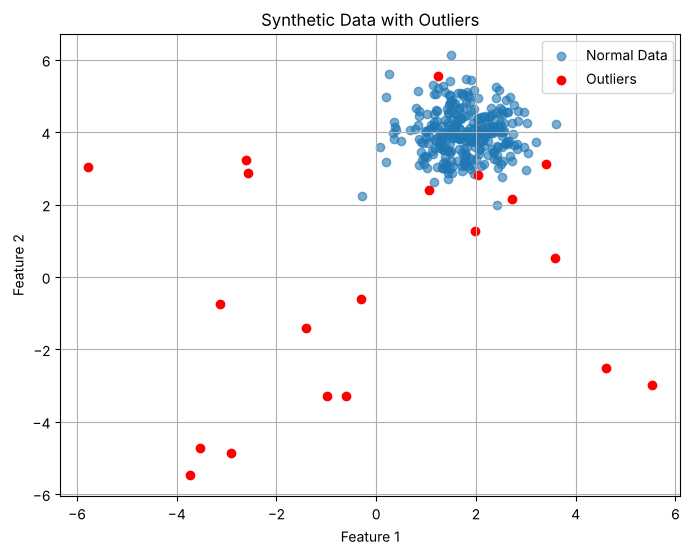

In [2]:
# Load the libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

# Generate a synthetic dataset with intentional outliers
X, _ = make_blobs(n_samples=300, centers=1, cluster_std=0.60, random_state=2024)
np.random.seed(2024)
outliers = np.random.uniform(low=-6, high=6, size=(20, 2))
X_with_outliers = np.vstack([X, outliers])

# Visualize the data with outliers
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], label="Normal Data", alpha=0.6)
plt.scatter(outliers[:, 0], outliers[:, 1], color='red', label="Outliers")
plt.title("Synthetic Data with Outliers")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

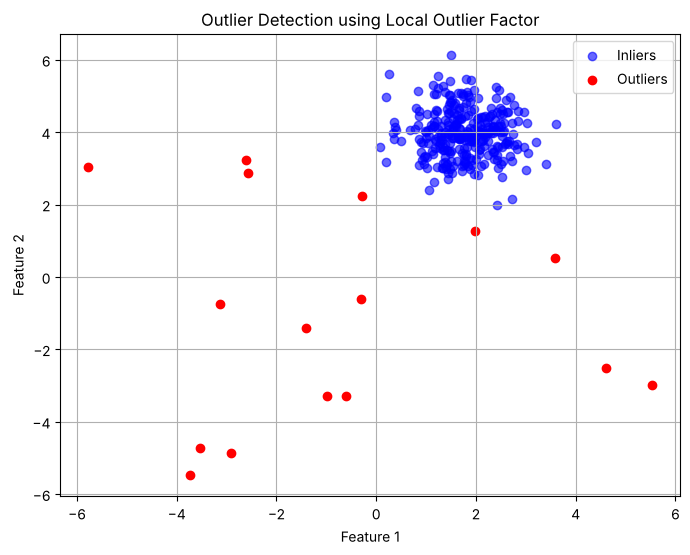

In [3]:
# Load the model
from sklearn.neighbors import LocalOutlierFactor

# Fit the model and predict outliers
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
y_pred = lof.fit_predict(X_with_outliers)

# Plot the predictions
plt.figure(figsize=(8, 6))
plt.scatter(X_with_outliers[y_pred == 1, 0], X_with_outliers[y_pred == 1, 1],
            color='blue', label='Inliers', alpha=0.6)
plt.scatter(X_with_outliers[y_pred == -1, 0], X_with_outliers[y_pred == -1, 1],
            color='red', label='Outliers')
plt.title("Outlier Detection using Local Outlier Factor")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

In [4]:
y_true_intro = np.array([0] * 300 + [1] * 20)       # 1 = outlier sebenarnya
y_pred_intro = (y_pred == -1).astype(int)
print('Jumlah titik ditandai outlier:', y_pred_intro.sum(), '(= 5% dari 320, sesuai contamination)')
print('Outlier sebenarnya yang tertangkap:', (y_pred_intro & y_true_intro).sum(), 'dari 20')

Jumlah titik ditandai outlier: 16 (= 5% dari 320, sesuai contamination)
Outlier sebenarnya yang tertangkap: 15 dari 20


**Interpretasi.** Dengan `contamination=0.05`, LOF menandai tepat 16 titik (5% × 320). Dari 20 outlier yang disisipkan, 15 tertangkap. Lima outlier yang "lolos" bukan kegagalan algoritma: titik-titik itu dibangkitkan acak di kotak $[-6, 6]^2$ dan kebetulan jatuh **di dalam** awan data normal (jaraknya 1,2–2,1 satuan dari pusat, sementara titik normal terjauh berjarak 2,7). Secara statistik, titik tersebut memang tidak bisa dibedakan dari data normal. Selain itu, karena kuota 16 sudah ditetapkan oleh `contamination`, 1 titik normal yang paling pinggir ikut ditandai sebagai outlier.

## Resep 2 — Isolation Forest

### Teori
Isolation Forest (Liu, Ting & Zhou, 2008) tidak memodelkan data normal, melainkan langsung **mengisolasi** anomali. Idenya: anomali itu **sedikit dan berbeda**, sehingga lebih mudah dipisahkan dari data lain.

1. Bangun banyak **isolation tree**. Setiap pohon dilatih pada subsampel acak (default 256 titik); di setiap simpul dipilih satu fitur acak dan satu ambang acak di antara nilai minimum dan maksimum fitur tersebut.
2. Pemisahan diulang sampai setiap titik terisolasi sendirian (atau batas kedalaman tercapai).
3. **Panjang jalur** $h(\mathbf x)$ = jumlah pemisahan yang diperlukan untuk mengisolasi $\mathbf x$. Titik di tengah kerumunan membutuhkan banyak pemisahan; outlier yang terpencil terisolasi dalam sedikit pemisahan.

Skor anomali dinormalisasi dengan $c(n)$, rata-rata panjang jalur pencarian gagal di *binary search tree* dengan $n$ titik:
$$s(\mathbf x, n) = 2^{-\frac{\mathbb E[h(\mathbf x)]}{c(n)}}, \qquad c(n) = 2H(n-1) - \frac{2(n-1)}{n},\quad H(i)\approx\ln i + 0{,}5772$$
$s \to 1$: sangat mungkin anomali; $s \ll 0{,}5$: titik normal. Di scikit-learn, `score_samples` mengembalikan $-s$, dan `decision_function` = `score_samples` − ambang (negatif berarti outlier).

Kelebihan: kompleksitas linear $O(n)$, tidak memakai jarak sehingga relatif tahan di dimensi tinggi, dan bisa memprediksi data baru. Kekurangan: pemisahan sejajar sumbu, dan kurang peka terhadap anomali **lokal** di area dengan kepadatan berbeda-beda.

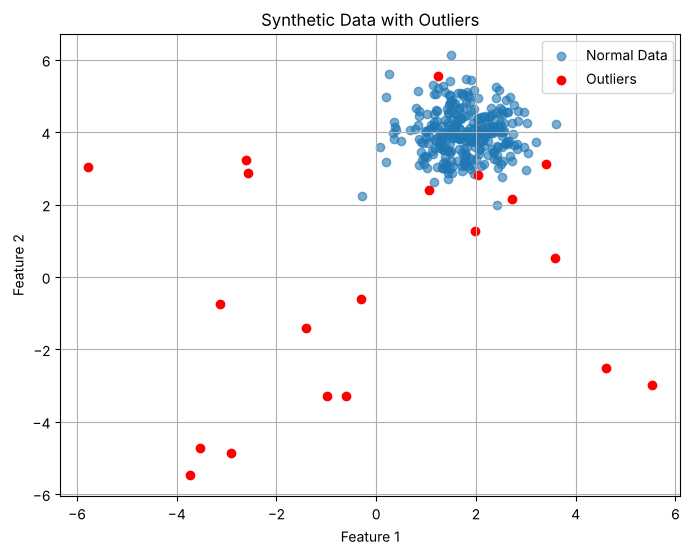

In [5]:
# Load the libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.datasets import make_blobs

# Generate synthetic data with outliers
X, _ = make_blobs(n_samples=300, centers=1, cluster_std=0.6, random_state=2024)
np.random.seed(2024)
outliers = np.random.uniform(low=-6, high=6, size=(20, 2))
X_combined = np.vstack([X, outliers])

# Visualize the data
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], label="Normal Data", alpha=0.6)
plt.scatter(outliers[:, 0], outliers[:, 1], color='red', label="Outliers")
plt.title("Synthetic Data with Outliers")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

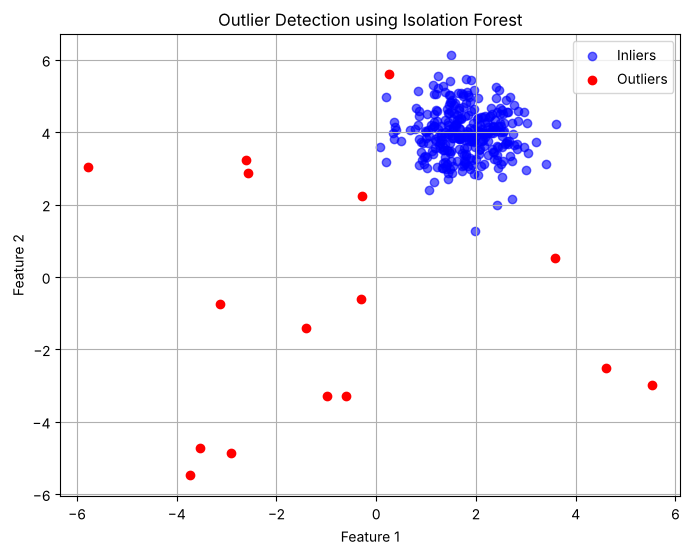

In [6]:
# Load and configure the model
model = IsolationForest(n_estimators=100, contamination=0.05, random_state=2024)

# Fit the model and make predictions
model.fit(X_combined)
y_pred = model.predict(X_combined)

# Plot the results
plt.figure(figsize=(8, 6))
plt.scatter(X_combined[y_pred == 1, 0], X_combined[y_pred == 1, 1],
            color='blue', label='Inliers', alpha=0.6)
plt.scatter(X_combined[y_pred == -1, 0], X_combined[y_pred == -1, 1],
            color='red', label='Outliers')
plt.title("Outlier Detection using Isolation Forest")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

In [7]:
y_true_if = np.array([0] * 300 + [1] * 20)
y_pred_if = (y_pred == -1).astype(int)
print('Ditandai outlier:', y_pred_if.sum(), '| outlier sebenarnya yang tertangkap:', (y_pred_if & y_true_if).sum(), 'dari 20')
scores = -model.score_samples(X_combined)   # skor s(x) versi paper (makin besar makin anomali)
print('Rata-rata skor s(x) titik normal : %.3f' % scores[:300].mean())
print('Rata-rata skor s(x) outlier asli : %.3f' % scores[300:].mean())

Ditandai outlier: 16 | outlier sebenarnya yang tertangkap: 14 dari 20
Rata-rata skor s(x) titik normal : 0.399
Rata-rata skor s(x) outlier asli : 0.651


**Interpretasi.** Isolation Forest menangkap 14 dari 20 outlier (dari 16 titik yang ditandai, sesuai `contamination=0.05`). Rata-rata skor anomali $s(\mathbf x)$ untuk titik normal ≈ 0,40 (< 0,5, artinya "normal") dan untuk outlier asli ≈ 0,65 (> 0,5, condong anomali) — sesuai interpretasi rumus di bagian teori. Seperti pada LOF, outlier yang lolos adalah titik acak yang kebetulan berada di dekat atau di dalam cluster normal.

## Resep 3 — One-Class SVM untuk Novelty Detection

### Teori
One-Class SVM (Schölkopf dkk., 2001) memetakan data ke ruang fitur kernel $\phi(\mathbf x)$, lalu mencari hyperplane yang memisahkan data latih dari **titik asal** dengan margin terbesar:
$$\min_{\mathbf w,\boldsymbol\xi,\rho}\;\frac12\lVert\mathbf w\rVert^2 + \frac{1}{\nu n}\sum_{i=1}^{n}\xi_i - \rho \quad\text{s.t.}\quad \mathbf w^\top\phi(\mathbf x_i)\ge\rho-\xi_i,\;\;\xi_i\ge 0$$
Fungsi keputusan $f(\mathbf x) = \operatorname{sign}(\mathbf w^\top\phi(\mathbf x)-\rho)$: +1 di dalam "wilayah normal", −1 di luar. Dengan kernel RBF, wilayah ini di ruang asal berupa satu atau beberapa daerah tertutup yang membungkus data.

Parameter **$\nu \in (0, 1]$** punya makna yang jelas:
- **batas atas** proporsi data latih yang boleh berada di luar batas (≈ tingkat *false alarm* pada data latih), dan
- **batas bawah** proporsi data latih yang menjadi support vector.

Karena berbasis jarak (kernel RBF), One-Class SVM **sensitif terhadap scaling**, dan biaya pelatihannya kira-kira kuadratik terhadap $n$.

### Persiapan
Model dilatih pada 300 titik normal saja. Data uji = 100 titik "normal" baru + 20 titik novelty acak.

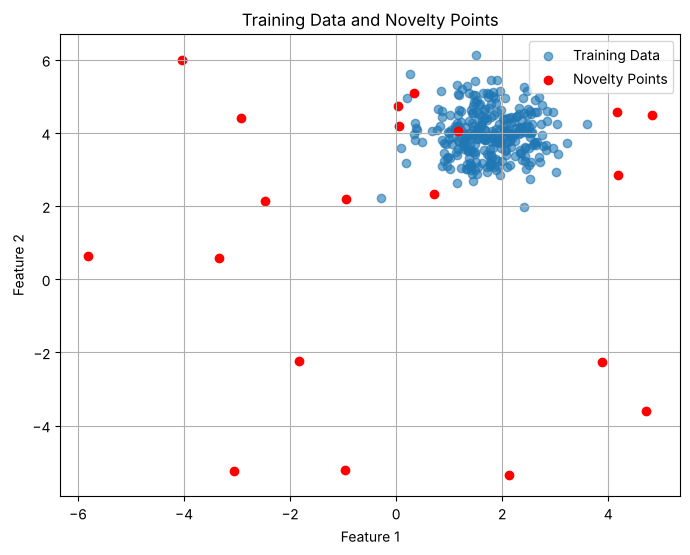

In [8]:
# Load the libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import OneClassSVM
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split

# Generate training data (normal only)
X_train, _ = make_blobs(n_samples=300, centers=1, cluster_std=0.6, random_state=2024)

# Generate test data (normal + novelty)
X_test_normal, _ = make_blobs(n_samples=100, centers=1, cluster_std=0.6, center_box=(0, 1), random_state=42)
X_test_novelty = np.random.uniform(low=-6, high=6, size=(20, 2))
X_test = np.vstack([X_test_normal, X_test_novelty])

# Visualize the data
plt.figure(figsize=(8, 6))
plt.scatter(X_train[:, 0], X_train[:, 1], label='Training Data', alpha=0.6)
plt.scatter(X_test_novelty[:, 0], X_test_novelty[:, 1], color='red', label='Novelty Points')
plt.title("Training Data and Novelty Points")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

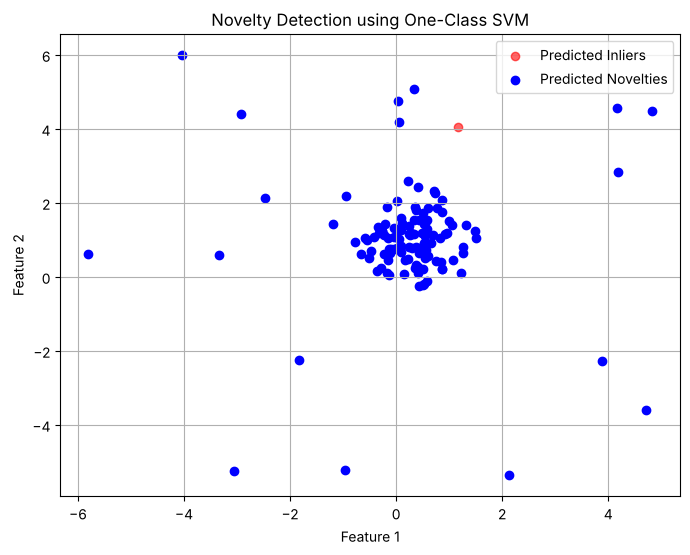

In [9]:
# Instantiate and fit the model
model = OneClassSVM(kernel='rbf', gamma='scale', nu=0.05)
model.fit(X_train)

# Make predictions on the test data
y_pred = model.predict(X_test)

# Plot the predictions
plt.figure(figsize=(8, 6))
plt.scatter(X_test[y_pred == 1, 0], X_test[y_pred == 1, 1], color='red', label='Predicted Inliers', alpha=0.6)
plt.scatter(X_test[y_pred == -1, 0], X_test[y_pred == -1, 1], color='blue', label='Predicted Novelties')
plt.title("Novelty Detection using One-Class SVM")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
y_true_ocsvm = np.array([0] * len(X_test_normal) + [1] * len(X_test_novelty))   # 1 = novelty
y_pred_ocsvm = (y_pred == -1).astype(int)
print('Pusat data latih          :', X_train.mean(axis=0).round(2))
print('Pusat data uji "normal"   :', X_test_normal.mean(axis=0).round(2))
print('Data uji "normal" yang dianggap novelty: %d dari %d' % (y_pred_ocsvm[:100].sum(), 100))
print('Novelty yang terdeteksi              : %d dari %d' % (y_pred_ocsvm[100:].sum(), 20))
print('Proporsi data LATIH di luar batas    : %.3f (nu = 0.05)' % np.mean(model.predict(X_train) == -1))

Pusat data latih          : [1.76 3.98]
Pusat data uji "normal"   : [0.3  0.98]
Data uji "normal" yang dianggap novelty: 100 dari 100
Novelty yang terdeteksi              : 19 dari 20
Proporsi data LATIH di luar batas    : 0.047 (nu = 0.05)


**Interpretasi — ada masalah pada data uji buku.**
Hasilnya terlihat aneh: **semua 100** titik uji "normal" dianggap novelty. Penyebabnya ada pada cara data dibangkitkan, bukan pada model:
- Data latih: `make_blobs(..., random_state=2024)` → pusat cluster di sekitar **(1,76; 3,98)**.
- Data uji "normal": `make_blobs(..., center_box=(0, 1), random_state=42)` → pusat di sekitar **(0,30; 0,98)**, kira-kira 3,3 satuan dari pusat data latih (≈ 5,5× simpangan baku 0,6).

Jadi "data normal" di data uji sebenarnya berasal dari **distribusi yang berbeda**, dan One-Class SVM justru **benar** menganggapnya novelty. Ini contoh nyata *distribution shift*: novelty detection hanya bermakna jika data normal di masa depan berasal dari distribusi yang sama dengan data latih.

Bagian lain bekerja sesuai teori: 19 dari 20 novelty acak terdeteksi, dan proporsi data latih di luar batas = 0,047 ≈ $\nu$ = 0,05.

Catatan visual: plot ini memakai warna yang **berkebalikan** dengan plot lain di bab ini — di sini merah = *inlier* dan biru = *novelty*, sedangkan di resep lain merah menandai anomali. Labelnya sendiri benar. Hampir semua titik berwarna biru (dianggap novelty), termasuk seluruh gumpalan data uji "normal" di sekitar (0,3; 1). Satu-satunya titik merah adalah titik acak di sekitar (1,2; 4,1) — kebetulan dekat dengan pusat data **latih** (1,76; 3,98), sehingga dianggap normal.

In [11]:
# Eksperimen tambahan: ulangi dengan data uji normal yang benar-benar berasal dari distribusi yang sama
from sklearn.datasets import make_blobs
X_all, _ = make_blobs(n_samples=400, centers=1, cluster_std=0.6, random_state=2024)
X_tr_fix, X_te_normal_fix = X_all[:300], X_all[300:]
X_te_fix = np.vstack([X_te_normal_fix, X_test_novelty])
model_fix = OneClassSVM(kernel='rbf', gamma='scale', nu=0.05).fit(X_tr_fix)
pred_fix = (model_fix.predict(X_te_fix) == -1).astype(int)
print('Normal yang dianggap novelty: %d dari 100' % pred_fix[:100].sum())
print('Novelty yang terdeteksi     : %d dari 20' % pred_fix[100:].sum())

Normal yang dianggap novelty: 8 dari 100
Novelty yang terdeteksi     : 19 dari 20


**Interpretasi.** Ketika data uji normal diambil dari distribusi yang **sama** dengan data latih (400 titik dibangkitkan sekaligus, 300 untuk latih dan 100 untuk uji), hanya 8 dari 100 titik normal yang dianggap novelty (8%, dekat dengan $\nu$ = 5% ditambah variasi sampel), sementara 19 dari 20 novelty tetap terdeteksi. Inilah perilaku One-Class SVM yang diharapkan.

## Resep 4 — Local Outlier Factor (LOF)

### Teori
LOF (Breunig dkk., 2000) membandingkan **kepadatan lokal** sebuah titik dengan kepadatan tetangganya. Untuk $k$ = `n_neighbors`:

1. **k-distance** $d_k(\mathbf o)$ = jarak titik $\mathbf o$ ke tetangga ke-$k$-nya.
2. **Reachability distance** (menghaluskan jarak agar tidak terlalu kecil di daerah sangat padat):
$$\text{reach-dist}_k(\mathbf a,\mathbf b) = \max\{d_k(\mathbf b),\; d(\mathbf a,\mathbf b)\}$$
3. **Local reachability density:**
$$\text{lrd}_k(\mathbf a) = \left(\frac{1}{|N_k(\mathbf a)|}\sum_{\mathbf b\in N_k(\mathbf a)}\text{reach-dist}_k(\mathbf a,\mathbf b)\right)^{-1}$$
4. **LOF** = rasio rata-rata kepadatan tetangga terhadap kepadatan titik itu sendiri:
$$\text{LOF}_k(\mathbf a) = \frac{1}{|N_k(\mathbf a)|}\sum_{\mathbf b\in N_k(\mathbf a)}\frac{\text{lrd}_k(\mathbf b)}{\text{lrd}_k(\mathbf a)}$$

LOF ≈ 1: kepadatan setara tetangganya (normal). LOF ≫ 1: titik jauh lebih "jarang" daripada lingkungannya (outlier).

Karena perbandingannya **relatif terhadap lingkungan**, LOF dapat mendeteksi titik yang sedikit menjauh dari cluster padat, sekaligus tidak salah menandai titik di cluster yang memang renggang — sesuatu yang sulit bagi metode dengan ambang global. Di scikit-learn, LOF default hanya untuk outlier detection (`fit_predict`); untuk memprediksi data baru gunakan `LocalOutlierFactor(novelty=True)`.

### Persiapan
Dua cluster dengan kepadatan sangat berbeda: cluster padat di (0, 0) dengan simpangan baku 0,5 dan cluster renggang di (5, 5) dengan simpangan baku 1,5, ditambah 20 outlier acak di $[-6, 10]^2$.

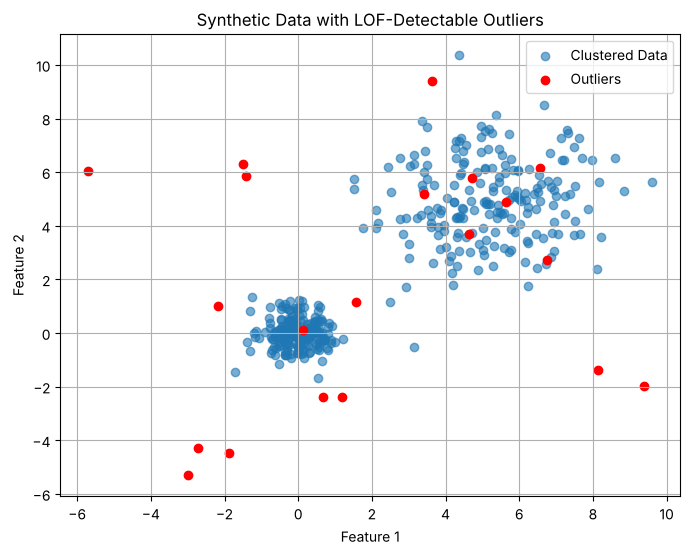

In [12]:
# Load the libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.neighbors import LocalOutlierFactor

# Create synthetic data with clusters and noise
X, _ = make_blobs(n_samples=400, centers=[[0, 0], [5, 5]], cluster_std=[0.5, 1.5], random_state=2024)
np.random.seed(2024)
outliers = np.random.uniform(low=-6, high=10, size=(20, 2))
X_with_outliers = np.vstack([X, outliers])

# Visualize the data
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], label="Clustered Data", alpha=0.6)
plt.scatter(outliers[:, 0], outliers[:, 1], color='red', label="Outliers")
plt.title("Synthetic Data with LOF-Detectable Outliers")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

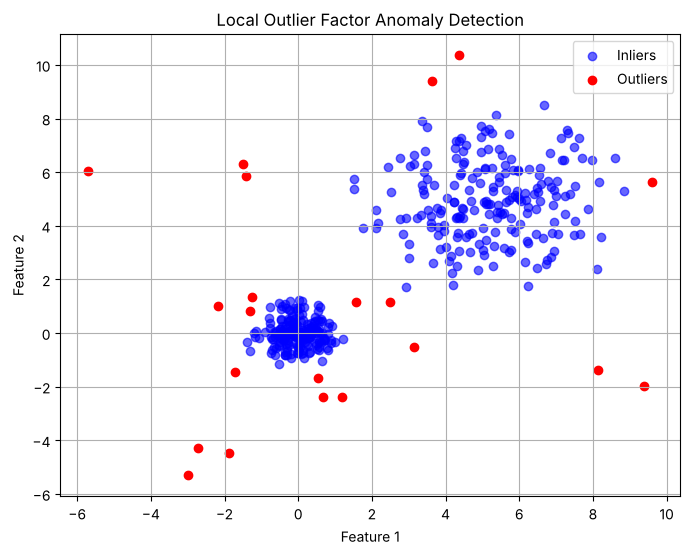

In [13]:
# Initialize and fit the model
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
y_pred = lof.fit_predict(X_with_outliers)

# Plot the predictions
plt.figure(figsize=(8, 6))
plt.scatter(X_with_outliers[y_pred == 1, 0], X_with_outliers[y_pred == 1, 1],
            color='blue', label='Inliers', alpha=0.6)
plt.scatter(X_with_outliers[y_pred == -1, 0], X_with_outliers[y_pred == -1, 1],
            color='red', label='Outliers')
plt.title("Local Outlier Factor Anomaly Detection")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

In [14]:
y_true_lof = np.array([0] * 400 + [1] * 20)
y_pred_lof = (y_pred == -1).astype(int)
print('Ditandai outlier:', y_pred_lof.sum(), '| outlier sebenarnya yang tertangkap:', (y_pred_lof & y_true_lof).sum(), 'dari 20')
lof_scores = -lof.negative_outlier_factor_
print('Median skor LOF titik normal  : %.2f' % np.median(lof_scores[:400]))
print('Median skor LOF outlier asli  : %.2f' % np.median(lof_scores[400:]))

Ditandai outlier: 21 | outlier sebenarnya yang tertangkap: 13 dari 20
Median skor LOF titik normal  : 1.04
Median skor LOF outlier asli  : 3.03


**Interpretasi.** LOF menandai 21 titik (5% × 420) dan menangkap 13 dari 20 outlier. Median skor LOF titik normal ≈ 1,04 (kepadatannya setara tetangga), sedangkan outlier ≈ 3,03 — sesuai teori: LOF ≈ 1 normal, LOF ≫ 1 outlier.

Ke mana sisanya? Tujuh outlier yang lolos sebagian besar jatuh **di dalam cluster renggang** di sekitar (5, 5), misalnya (5,6; 4,9) dan (4,7; 5,8), atau tepat di tengah cluster padat (0,1; 0,1). Di dalam cluster, titik acak itu memiliki kepadatan yang setara dengan tetangganya, sehingga memang bukan anomali secara lokal. Sebaliknya, beberapa titik normal yang ditandai outlier adalah titik di **tepi** cluster padat (misalnya (−1,7; −1,5)) — titik ini jauh lebih renggang dibandingkan tetangga-tetangganya yang sangat rapat, sehingga LOF menganggapnya aneh secara lokal. Inilah karakter LOF: yang dinilai adalah keanehan **relatif terhadap lingkungan**, bukan jarak absolut.

## Resep 5 — Mengevaluasi Model Deteksi Outlier

### Teori
Jika label tersedia (misalnya data sintetis atau kasus fraud yang sudah diverifikasi), deteksi anomali bisa dievaluasi sebagai klasifikasi biner yang **sangat tidak seimbang**. Akurasi menyesatkan: menebak "semua normal" pada data dengan 1% fraud sudah memberi akurasi 99%. Karena itu fokus pada kelas outlier:
- **Precision outlier** — dari yang dicurigai, berapa yang benar anomali? (biaya *false alarm*)
- **Recall outlier** — dari semua anomali, berapa yang tertangkap? (biaya anomali yang lolos)
- **ROC–AUC** dari skor kontinu (`decision_function`) — mengukur kualitas **peringkat** skor, tidak bergantung pada `contamination`. Untuk data yang sangat timpang, **PR-AUC / average precision** sering lebih informatif.

Tanpa label, evaluasi bergantung pada validasi pakar, stabilitas hasil antar-run, atau metrik proksi seperti *reconstruction error*.

### Persiapan
300 titik normal + 30 outlier acak (≈ 9%). `contamination=0.09` sesuai proporsi sebenarnya.

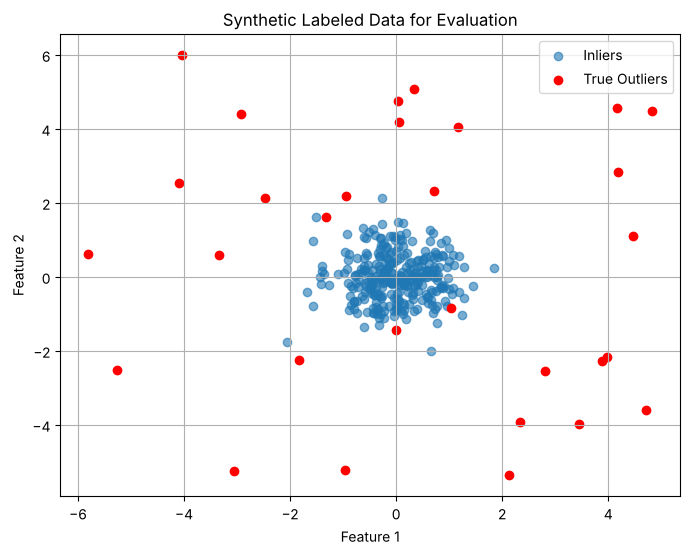

In [15]:
# Load the libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import seaborn as sns

# Generate labeled synthetic data
X_inliers, _ = make_blobs(n_samples=300, centers=[[0, 0]], cluster_std=0.6, random_state=2024)
X_outliers = np.random.uniform(low=-6, high=6, size=(30, 2))
X = np.vstack([X_inliers, X_outliers])
y_true = np.array([0] * len(X_inliers) + [1] * len(X_outliers))  # 0 = inlier, 1 = outlier

# Visualize the data
plt.figure(figsize=(8, 6))
plt.scatter(X[y_true == 0][:, 0], X[y_true == 0][:, 1], label='Inliers', alpha=0.6)
plt.scatter(X[y_true == 1][:, 0], X[y_true == 1][:, 1], color='red', label='True Outliers')
plt.title("Synthetic Labeled Data for Evaluation")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

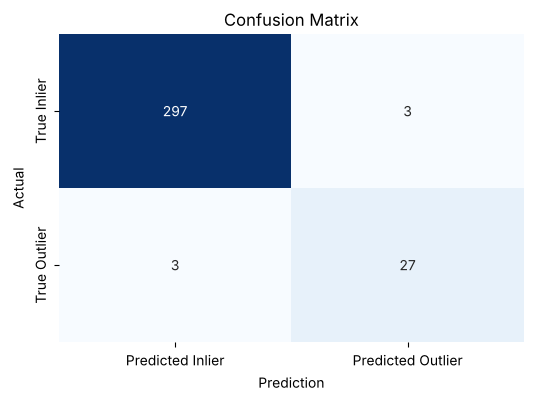

,precision,recall,f1-score,support
0,0.990,0.990,0.990,300
1,0.900,0.900,0.900,30
accuracy,0.982,0.982,0.982,1
macro avg,0.945,0.945,0.945,330
weighted avg,0.982,0.982,0.982,330


ROC-AUC Score: 0.005111111111111106


In [16]:
import pandas as pd

# Fit the model and get predictions
model = IsolationForest(contamination=0.09, random_state=2024)
model.fit(X)
y_pred = model.predict(X)
y_pred_binary = np.where(y_pred == 1, 0, 1)  # convert to 0 = inlier, 1 = outlier

# Generate and plot confusion matrix
cm = confusion_matrix(y_true, y_pred_binary)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Inlier', 'Predicted Outlier'],
            yticklabels=['True Inlier', 'True Outlier'])
plt.xlabel('Prediction')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# Print classification report as a styled DataFrame and AUC
report = classification_report(y_true, y_pred_binary, output_dict=True)
report = pd.DataFrame(report).transpose()
styled_report = (report
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_report)
print("ROC-AUC Score:", roc_auc_score(y_true, model.decision_function(X)))

In [17]:
from sklearn.metrics import average_precision_score
# decision_function: makin besar makin "normal", jadi dibalik tandanya untuk skor outlier
print('ROC-AUC (skor dibalik) : %.3f' % roc_auc_score(y_true, -model.decision_function(X)))
print('Average precision (PR-AUC): %.3f' % average_precision_score(y_true, -model.decision_function(X)))

ROC-AUC (skor dibalik) : 0.995
Average precision (PR-AUC): 0.966


**Interpretasi.**
- Confusion matrix dan laporan klasifikasi: dari 30 outlier, **27 tertangkap** (recall 0,90) dan dari 30 titik yang ditandai, 27 memang outlier (precision 0,90). Kelas normal: precision dan recall 0,99. Karena `contamination=0.09` sama dengan proporsi outlier sebenarnya (30/330), jumlah yang ditandai = jumlah outlier asli, sehingga precision = recall.
- **Bug pada kode buku:** buku mencetak `ROC-AUC Score: 0.005`. Nilai sekecil itu berarti peringkatnya **terbalik**, bukan model yang buruk. `decision_function` Isolation Forest bernilai **besar untuk titik normal** dan kecil/negatif untuk outlier, sedangkan `y_true` memakai 1 = outlier. Skornya harus dibalik tandanya (`-model.decision_function(X)`), dan hasilnya **ROC-AUC = 0,995** — model hampir selalu memberi skor anomali lebih tinggi kepada outlier daripada titik normal. Average precision 0,966 juga sangat tinggi.

Pelajaran: selalu periksa **arah** skor sebelum menghitung AUC. ROC-AUC yang jauh di bawah 0,5 hampir selalu berarti tanda yang terbalik.

## Resep 6 — Menangani Outlier yang Terdeteksi

### Teori
Pertanyaan pertama selalu: **mengapa** titik itu outlier?
- Kesalahan pengukuran / input / sensor rusak → biasanya aman dihapus atau diperbaiki.
- Kejadian nyata tetapi langka (fraud, kerusakan mesin, pasien kritis) → justru **informasi paling penting**; jangan dihapus.

| Strategi | Cara | Kelebihan | Risiko |
|---|---|---|---|
| **Hapus** | buang baris outlier | sederhana, model tidak terdistorsi | kehilangan data dan sinyal penting |
| **Ganti (imputasi)** | ganti dengan median/mean | ukuran data tetap | mengecilkan varians, menimbulkan bias |
| **Capping / winsorization** | potong nilai ke persentil tertentu, misal ke $[P_5, P_{95}]$ | urutan nilai dipertahankan | nilai ekstrem asli hilang |
| **Transformasi** | log, Box–Cox, `RobustScaler` | mengurangi pengaruh ekor panjang | interpretasi berubah |
| **Flagging** | tambah fitur biner "is_outlier" | informasi dipertahankan, model belajar perbedaannya | butuh model yang bisa memanfaatkannya |

Penting: penanganan outlier termasuk langkah preprocessing, sehingga detektor juga harus **di-fit pada data latih saja** untuk menghindari kebocoran data.

In [18]:
# Load the libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.datasets import make_blobs

# Generate the dataset
X_inliers, _ = make_blobs(n_samples=300, centers=[[0, 0]], cluster_std=0.6, random_state=2024)
X_outliers = np.random.uniform(low=-6, high=6, size=(30, 2))
X = np.vstack([X_inliers, X_outliers])

#  Detect outliers using Isolation Forest
model = IsolationForest(contamination=0.09, random_state=2024)
model.fit(X)
outlier_mask = model.predict(X) == -1

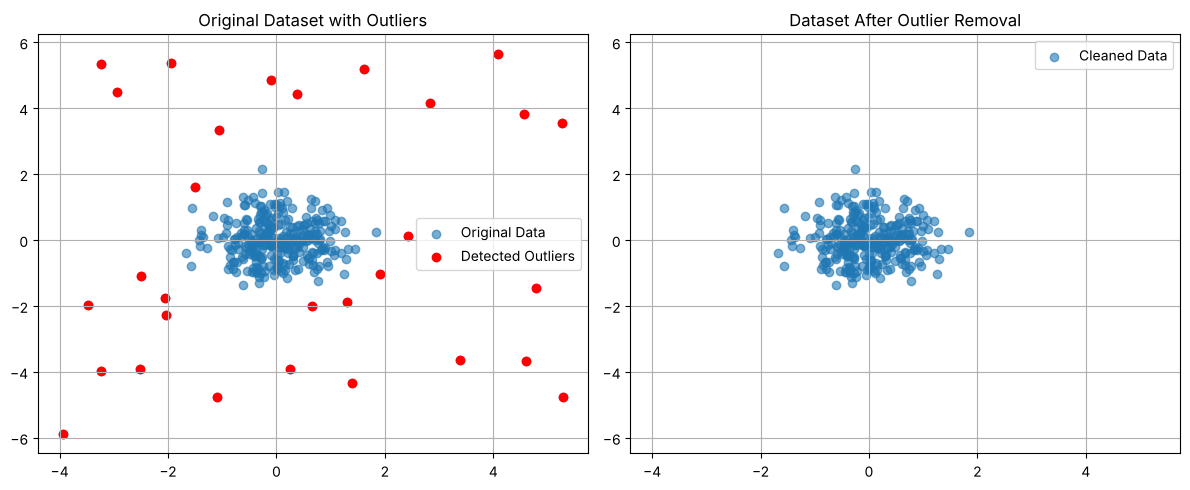

In [19]:
# Remove outliers from the dataset
X_cleaned = X[~outlier_mask]

# Replace outliers with the feature-wise median
X_replaced = X.copy()
median_vals = np.median(X[~outlier_mask], axis=0)
X_replaced[outlier_mask] = median_vals

# Cap outliers to specified bounds (winsorization)
X_df = pd.DataFrame(X, columns=['feature1', 'feature2'])
X_capped = X_df.copy()
for col in X_df.columns:
    lower = X_df[col].quantile(0.05)
    upper = X_df[col].quantile(0.95)
    X_capped[col] = X_df[col].clip(lower=lower, upper=upper)

# Visualize original and cleaned datasets with matched axes
plt.figure(figsize=(12, 5))

ax1 = plt.subplot(1, 2, 1)
ax1.scatter(X[:, 0], X[:, 1], label='Original Data', alpha=0.6)
ax1.scatter(X[outlier_mask][:, 0], X[outlier_mask][:, 1], color='red', label='Detected Outliers')
ax1.set_title('Original Dataset with Outliers')
ax1.legend()
ax1.grid(True)

ax2 = plt.subplot(1, 2, 2)
ax2.scatter(X_cleaned[:, 0], X_cleaned[:, 1], label='Cleaned Data', alpha=0.6)
ax2.set_title('Dataset After Outlier Removal')
ax2.legend()
ax2.grid(True)

ax2.set_xlim(ax1.get_xlim())
ax2.set_ylim(ax1.get_ylim())

plt.tight_layout()
plt.show()

In [20]:
print('Ukuran data asli         :', X.shape)
print('Setelah outlier dihapus  :', X_cleaned.shape)
print('Std fitur asli           :', X.std(axis=0).round(3))
print('Std setelah dihapus      :', X_cleaned.std(axis=0).round(3))
print('Std setelah ganti median :', X_replaced.std(axis=0).round(3))
print('Std setelah winsorization:', X_capped.std().values.round(3))

# Contoh strategi flagging
X_flagged = pd.DataFrame(X, columns=['feature1', 'feature2'])
X_flagged['is_outlier'] = outlier_mask.astype(int)
display(X_flagged.tail(3))

Ukuran data asli         : (330, 2)
Setelah outlier dihapus  : (300, 2)
Std fitur asli           : [1.059 1.288]
Std setelah dihapus      : [0.607 0.614]
Std setelah ganti median : [0.579 0.585]
Std setelah winsorization: [0.68  0.687]


,feature1,feature2,is_outlier
327,-3.939803,-5.894665,1
328,-1.094535,-4.758373,1
329,0.300562,-0.481668,0


**Interpretasi.**
- **Hapus:** 30 titik dibuang (330 → 300), dan simpangan baku turun dari ≈1,06–1,29 menjadi ≈0,61 — mendekati `cluster_std=0.6` yang dipakai untuk membangkitkan data normal. Dengan kata lain, setelah outlier dihapus, statistik data kembali mencerminkan distribusi aslinya.
- **Ganti dengan median:** ukuran data tetap 330, tetapi std turun lebih jauh (≈0,58) — lebih kecil dari std sebenarnya — karena 30 titik dipaksa ke satu nilai yang sama. Ini efek "mengecilkan varians" yang dijelaskan di tabel teori.
- **Winsorization** ke persentil 5–95: std ≈0,68, di antara kedua strategi lain. Nilai ekstrem ditarik ke batas, tetapi titiknya tetap ada (dan setiap titik yang di luar persentil ikut dipotong, termasuk titik normal di pinggir).
- **Flagging:** data asli tidak diubah; kolom `is_outlier` ditambahkan sebagai fitur tambahan.

## Resep 7 — Memilih Teknik Deteksi yang Tepat

Tabel ringkasan dari buku:

In [21]:
# Load the libraries
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM

# Create a comparison table of methods
data = {
    "Algorithm": ["Isolation Forest", "Local Outlier Factor", "One-Class SVM"],
    "Handles High Dimensions": ["Yes", "No", "Sometimes"],
    "Learns From Unlabeled Data": ["Yes", "Yes", "No (novelty only)"],
    "Supports New Predictions": ["Yes", "No", "Yes"],
    "Scales to Large Data": ["Yes", "No", "No"],
    "Robust to Varying Densities": ["No", "Yes", "Partially"],
    "Main Strength": [
        "Fast, scalable, easy to use",
        "Detects local anomalies in varying densities",
        "Kernel-based boundary modeling"
    ]
}

summary_df = pd.DataFrame(data)
summary_df.set_index("Algorithm", inplace=True)
summary_df

,Handles High Dimensions,Learns From Unlabeled Data,Supports New Predictions,Scales to Large Data,Robust to Varying Densities,Main Strength
Algorithm,,,,,,
Isolation Forest,Yes,Yes,Yes,Yes,No,"Fast, scalable, easy to use"
Local Outlier Factor,No,Yes,No,No,Yes,Detects local anomalies in varying densities
One-Class SVM,Sometimes,No (novelty only),Yes,No,Partially,Kernel-based boundary modeling


In [22]:
# If your data is large and high-dimensional, consider:
# Isolation Forest is preferred
model = IsolationForest(contamination=0.1, random_state=2024)

#If your data has clusters with varying densities:
# Local Outlier Factor is better suited
model = LocalOutlierFactor(n_neighbors=20, contamination=0.1)

# If you want to train on only normal data and detect novel data points later:
# One-Class SVM enables novelty detection
model = OneClassSVM(kernel='rbf', gamma='scale', nu=0.1)

**Interpretasi dan panduan praktis.** Sel kedua hanya menunjukkan cara membuat ketiga model (setiap baris menimpa variabel `model`), sebagai "resep keputusan":
- Data **besar dan/atau berdimensi tinggi**, tanpa label → mulai dengan **Isolation Forest** (cepat, minim tuning).
- Data dengan **cluster berkepadatan berbeda-beda**, dan anomali yang bersifat **lokal** → **LOF**.
- Hanya punya data **normal** untuk pelatihan, ingin memantau data baru → **One-Class SVM** (atau `LocalOutlierFactor(novelty=True)` / Isolation Forest yang dilatih pada data bersih).

Catatan atas tabel buku: kolom "Learns From Unlabeled Data = No" untuk One-Class SVM sebaiknya dipahami sebagai "membutuhkan data latih yang bersih dari anomali" — algoritmanya tetap tidak memakai label. Kolom "Supports New Predictions = No" untuk LOF berlaku untuk mode default; dengan `novelty=True` LOF dapat memprediksi data baru.

## Latihan Praktik

### Latihan 1 — Isolation Forest dengan scaling

In [23]:
# Load libraries
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from sklearn.datasets import make_blobs

# Generate synthetic data with inliers and outliers
X_inliers, _ = make_blobs(n_samples=300, centers=[[0, 0]], cluster_std=0.6, random_state=2024)
X_outliers = np.random.uniform(low=-6, high=6, size=(30, 2))
X = np.vstack([X_inliers, X_outliers])
y_true = np.array([0] * len(X_inliers) + [1] * len(X_outliers))

# Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply Isolation Forest
model = IsolationForest(contamination=0.09, random_state=2024)
model.fit(X_scaled)
y_pred = model.predict(X_scaled)
y_pred_binary = np.where(y_pred == 1, 0, 1)

# Evaluate the results
print("Exercise 1 Results:")

# Print classification report as a styled DataFrame
report = classification_report(y_true, y_pred_binary, output_dict=True)
report = pd.DataFrame(report).transpose()
styled_report = (report
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_report)

Exercise 1 Results:


,precision,recall,f1-score,support
0,0.993,0.993,0.993,300
1,0.933,0.933,0.933,30
accuracy,0.988,0.988,0.988,1
macro avg,0.963,0.963,0.963,330
weighted avg,0.988,0.988,0.988,330


In [24]:
from sklearn.metrics import roc_auc_score
print('Outlier sebenarnya yang tertangkap: %d dari 30' % ((y_pred_binary == 1) & (y_true == 1)).sum())
print('ROC-AUC: %.3f' % roc_auc_score(y_true, -model.decision_function(X_scaled)))

Outlier sebenarnya yang tertangkap: 28 dari 30
ROC-AUC: 0.968


**Interpretasi.** Setelah standardisasi, Isolation Forest menangkap **28 dari 30** outlier (precision dan recall kelas outlier 0,933), sedikit lebih baik daripada Resep 5 (27 dari 30). Perbedaan ini **bukan** efek scaling. Isolation Forest memilih ambang acak $t = \min + u(\max-\min)$ pada setiap fitur, sehingga transformasi linear per fitur (seperti `StandardScaler`) menghasilkan pohon yang identik — sel berikut membuktikannya. Penyebab sebenarnya: `np.random.uniform` dipanggil tanpa seed baru, sehingga 30 outlier di latihan ini adalah titik acak yang **berbeda** dari Resep 5. ROC-AUC 0,968.

In [25]:
# Bukti: Isolation Forest invariant terhadap StandardScaler (data dan random_state sama)
pred_raw = IsolationForest(contamination=0.09, random_state=2024).fit(X).predict(X)
pred_scaled = IsolationForest(contamination=0.09, random_state=2024).fit(X_scaled).predict(X_scaled)
print('Prediksi tanpa scaling == prediksi dengan scaling:', np.array_equal(pred_raw, pred_scaled))

Prediksi tanpa scaling == prediksi dengan scaling: True


### Latihan 2 — LOF pada data multi-cluster (simulasi intrusi jaringan)


Exercise 2 Results:


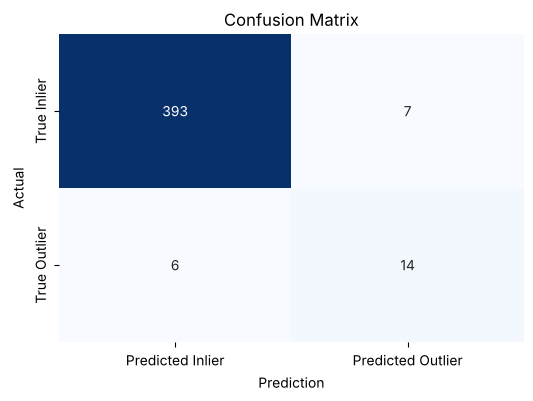

,precision,recall,f1-score,support
0,0.985,0.983,0.984,400
1,0.667,0.700,0.683,20
accuracy,0.969,0.969,0.969,1
macro avg,0.826,0.841,0.833,420
weighted avg,0.970,0.969,0.969,420


In [26]:
# Load libraries
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

# Generate clustered data with synthetic noise
X_clustered, _ = make_blobs(n_samples=400, centers=[[0, 0], [5, 5]], cluster_std=[0.5, 1.5], random_state=2024)
X_noise = np.random.uniform(low=-6, high=10, size=(20, 2))
X_combined = np.vstack([X_clustered, X_noise])
y_combined = np.array([0] * 400 + [1] * 20)

# Scale the data
X_scaled = scaler.fit_transform(X_combined)

# Apply Local Outlier Factor
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
y_pred = lof.fit_predict(X_scaled)
y_pred_binary = np.where(y_pred == 1, 0, 1)

# Evaluate the predictions
print("\nExercise 2 Results:")
cm = confusion_matrix(y_combined, y_pred_binary)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Inlier', 'Predicted Outlier'],
            yticklabels=['True Inlier', 'True Outlier'])
plt.xlabel('Prediction')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

report = classification_report(y_combined, y_pred_binary, output_dict=True)
report = pd.DataFrame(report).transpose()
styled_report = (report
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_report)

In [27]:
from sklearn.ensemble import IsolationForest
lof_scores_ex = -lof.negative_outlier_factor_
if_ex = IsolationForest(contamination=0.05, random_state=2024).fit(X_scaled)
if_pred = (if_ex.predict(X_scaled) == -1).astype(int)
print('LOF -> tertangkap %d dari 20 | ROC-AUC %.3f' % (((y_pred_binary == 1) & (y_combined == 1)).sum(),
                                                     roc_auc_score(y_combined, lof_scores_ex)))
print('IF  -> tertangkap %d dari 20 | ROC-AUC %.3f' % (((if_pred == 1) & (y_combined == 1)).sum(),
                                                     roc_auc_score(y_combined, -if_ex.decision_function(X_scaled))))

LOF -> tertangkap 14 dari 20 | ROC-AUC 0.970
IF  -> tertangkap 15 dari 20 | ROC-AUC 0.971


**Interpretasi.** Pada data dua cluster berkepadatan berbeda (terstandardisasi), LOF menangkap 14 dari 20 noise: precision 0,667 dan recall 0,70 untuk kelas outlier. Hasil ini jauh lebih rendah daripada Latihan 1, karena 20 titik noise tersebar di kotak $[-6, 10]^2$ yang juga mencakup kedua cluster — sebagian titik noise jatuh di dalam cluster renggang dan secara lokal tidak berbeda dari tetangganya.

Perbandingan dengan Isolation Forest pada data yang sama: IF menangkap 15 dari 20 dengan ROC-AUC 0,971, praktis setara dengan LOF (0,970). Keunggulan LOF untuk data "berkepadatan berbeda" tidak terlihat di sini; keunggulan itu biasanya baru menonjol jika anomali yang dicari adalah titik **di dekat** cluster padat, yang terlalu jauh untuk cluster padat tetapi akan terlihat normal bila dibandingkan dengan cluster renggang.

### Latihan 3 — One-Class SVM untuk data sensor manufaktur

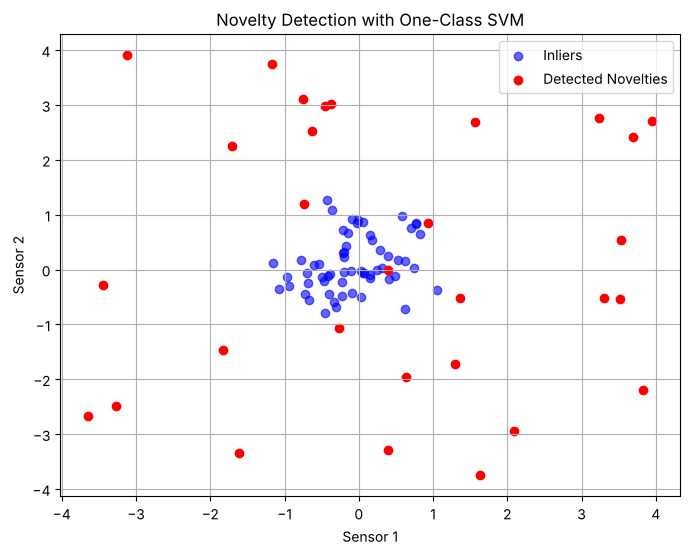

In [28]:
# Load libraries
from sklearn.svm import OneClassSVM
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Generate normal and novel data
X_normal = np.random.normal(loc=0.0, scale=0.5, size=(300, 2))
X_novelty = np.random.uniform(low=-4, high=4, size=(30, 2))
X_train, X_test = train_test_split(X_normal, test_size=0.2, random_state=2024)
X_eval = np.vstack([X_test, X_novelty])

# Fit One-Class SVM on normal data
svm_model = OneClassSVM(kernel='rbf', gamma='scale', nu=0.05)
svm_model.fit(X_train)
y_pred = svm_model.predict(X_eval)

# Visualize predictions
plt.figure(figsize=(8, 6))
plt.scatter(X_eval[y_pred == 1][:, 0], X_eval[y_pred == 1][:, 1], color='blue', label='Inliers', alpha=0.6)
plt.scatter(X_eval[y_pred == -1][:, 0], X_eval[y_pred == -1][:, 1], color='red', label='Detected Novelties')
plt.title("Novelty Detection with One-Class SVM")
plt.xlabel("Sensor 1")
plt.ylabel("Sensor 2")
plt.legend()
plt.grid(True)
plt.show()

In [29]:
pred_bin = (y_pred == -1).astype(int)
print('Data uji normal yang dianggap novelty: %d dari %d' % (pred_bin[:len(X_test)].sum(), len(X_test)))
print('Novelty yang terdeteksi              : %d dari %d' % (pred_bin[len(X_test):].sum(), len(X_novelty)))
print('Jarak novelty ke pusat (median)      : %.2f' % np.median(np.linalg.norm(X_novelty, axis=1)))

Data uji normal yang dianggap novelty: 2 dari 60
Novelty yang terdeteksi              : 28 dari 30
Jarak novelty ke pusat (median)      : 3.32


**Interpretasi.** Dalam skenario ini data uji normal **berasal dari distribusi yang sama** dengan data latih (300 titik Gaussian dibagi 240 latih / 60 uji), sehingga One-Class SVM bekerja sesuai harapan: hanya 2 dari 60 data uji normal dianggap novelty (≈3%, sesuai $\nu$ = 5%), dan 28 dari 30 novelty terdeteksi. Dua novelty yang lolos adalah titik acak yang kebetulan jatuh di dekat pusat distribusi normal. Bandingkan dengan Resep 3, yang gagal karena data uji normalnya berasal dari distribusi lain.

## Kesimpulan Bab 11

- **Outlier detection** bekerja pada data yang sudah tercampur anomali; **novelty detection** dilatih pada data normal saja lalu menilai data baru.
- **Isolation Forest** mengisolasi anomali dengan pemisahan acak — anomali punya jalur pendek. Cepat dan cocok sebagai titik awal.
- **LOF** membandingkan kepadatan lokal titik dengan tetangganya — kuat untuk data dengan kepadatan yang berbeda-beda.
- **One-Class SVM** mempelajari batas wilayah normal dengan kernel; $\nu$ ≈ tingkat false alarm pada data latih; sensitif terhadap scaling dan terhadap perbedaan distribusi antara data latih dan data uji.
- `contamination` hanya mengatur **ambang**; kualitas skornya dinilai dengan ROC–AUC / PR-AUC bila label tersedia.
- Penanganan outlier (hapus, ganti, capping, flagging) bergantung pada **penyebab** anomali; anomali bisa berupa noise yang harus dibuang atau justru sinyal yang paling berharga.